# LLM-Assisted Close Reading

The ‘Aeolus’ Episode of James Joyce’s *Ulysses*

Jasper Harrington [ORCID profile for Jasper Harrington](https://orcid.org/0009-0009-7363-5705) (University of Melbourne)  
[Michael Falk](https://michaelfalk.io) [ORCID profile for Michael Falk](https://orcid.org/0000-0001-9261-8390) (University of Melbourne)  
November 13, 2026

In this presentation, we report on our experiments performing LLM-assisted close reading of the ‘Aeolus’ episode of James Joyce’s *Ulysses*. The aim is twofold: (1) to explore Joyce’s use of media discourse in the episode; (2) to develop rigorous, reproducible methods for LLM-assisted close reading. For this initial presentation, we explain our reproducible pipeline, initial experimental results, validation of the LLM analysis against classic lexicon-based sentiment analysis, and initial impressions of close reading one section of ‘Aeolus’ in the light of the results.

# 1. Introduction

In [ ]:
library(aeolusmicrotexts)
aeolus <- load_aeolus()

In this presentation, we report on our experiments performing LLM-assisted close reading of the ‘Aeolus’ episode of James Joyce’s *Ulysses*. The ‘Aeolus’ episode marks a crucial “hermeneutic shift” in the novel ([Lawrence 1980, 392](#ref-lawrence_aeolus_1980)). In prior episodes, the novel’s language is primarily transparent and referential, as Joyce tries to create the illusion of a stream of consciousness; in ‘Aeolus’, new voices are introduced, in the form of newspaper headlines, which interrupt the stream of consciousness and render the language opaque. Who is speaking? Is there a consciousness behind the words? Where is the divide between nature and artifice, between art and life? This “hermeneutic shift” continues in later episodes of the novel, as the language becomes increasingly opaque and self-referential.

Our aims in this paper are twofold:

> **Aim 1:** To try to discover new angles of interpretation with the assistance of LLMs.
>
> **Aim 2:** To try and determine best practices for open, reproducible literary-critical research using LLMs.

To pursue these aims, we choose to focus on “mediatization” in the episode ([Schneider 1989](#ref-schneider_mediatization_1989)). The episode takes place in a newspaper office, and the episode’s key linguistic feature is the intrusion of newspaper headlines that ironically label the action. We therefore analyse the language of the episode as media discourse, using a traditional text-analytic technique (lexicon-based sentiment analysis) and an LLM-assisted analogue of this technique (LLM-based sentiment and thematic analysis).

This abstract is a quarto notebook. Code for all figures and calculations can be viewed [on the research compendium website](https://uom-digital-studies.github.io/aeolus-microtexts/dh2027/index-preview.html).

# 2. Literature Review

Like all episodes of *Ulysses*, ‘Aeolus’ has been subject to intense analysis. For this presentation, we survey the literature on media discourse in ‘Aeolus’. In a classic article, McLuhan ([1954](#ref-mcluhan_joyce_1954)) argues that *Ulysses* reflects the temporal rhythms of the news media. Like a daily newspaper, Joyce’s stream-of-consciousness technique realises “a continuous present for events past, present and future” ([1954, 46](#ref-mcluhan_joyce_1954)). McLuhan sees a deep harmony between the stream of consciousness and media discourse in *Ulysses*. Subsequent scholars have reversed McLuhan’s judgment. Lawrence ([1980](#ref-lawrence_aeolus_1980)), Schneider ([1989](#ref-schneider_mediatization_1989)) and Radak ([2017](#ref-radak_aeolus_2017)) all argue that the newspaper headlines in ‘Aeolus’ are intrusive, and disrupt the stream of consciousness.

We build on these readings in two ways. First, we re-adjudicate the dispute between McLuhan and his followers. Is it really true that the headlines are intrusive and disruptive, or do they in fact split the chapter into rational units? Second, we consider ‘mediatization’ in a new context, considering how the form of the chapter resonates with contemporary social media.

To do this, we split ‘Aeolus’ on the headlines, converting the episode into 63 “microtexts”. We study these microtexts as though they were social media posts, to see if these reveals new patterns in the language.

The principal analytic method we use is sentiment analysis, which was originally developed for social media analysis, but has subsequently become a crucial tool for plot analysis ([Elkins 2022](#ref-elkins_shapes_2022); [Franta and Silver 2024](#ref-franta_sentiment_2024); [Kim 2022](#ref-kim_sentiment_2022); [Falk 2024, chap. 6](#ref-falk_romanticism_2024)). In this project, we draw on recent research by Ornstein et al. ([2025](#ref-ornstein_how_2025)) and Mens and Gallego ([2025](#ref-mens_positioning_2025)) to formulate a reproducible pipeline for LLM-based sentiment analysis, as explained below. For comparison, we apply the afinn ([Nielsen 2011](#ref-nielsen_new_2011)), bing ([Hu and Liu 2004](#ref-hu_mining_2004)) and syuzhet ([Jockers 2015](#ref-jockers_syuzhet_2015)) sentiment lexicons to Aeolus for sentiment analysis, using Hutto and Gilbert ([2014](#ref-hutto_vader_2014))’s method for normalising the scores. As we explain in <a href="#sec-methodology" class="quarto-xref">Section 3</a>, LLMs have caused an upheaval in sentiment analysis, allowing much more context-sensitive data extraction at the cost of reliability and interpretability.

# 3. Methodology: The Reproducible Pipeline

LLMs are powerful but flawed tools for text analysis. In our view, existing practices of open, reproducible scholarship are already sufficient to realise much of the power while mitigating the flaws.

LLMs are powerful primarily because of *in-context learning* and *structured outputs*. In-context learning is a powerful technique for controlling the LLM’s response to data: the researcher provides contextual clues in the prompt, enabling the LLM to respond more sensitively to the input data ([Ornstein et al. 2025, 269](#ref-ornstein_how_2025)) Structured outputs make the output easier to process, by ensuring that it conforms to a provided json schema ([“Structured Model Outputs OpenAI API,” n.d.](#ref-openai_structured_data_docs)). This does not prevent hallucinations, but does ensure that data is uniformly formatted for processing.

They are flawed because they are inherently *inexplicable* and *unreliable*. The problem of LLM explicability is well known ([Goebel et al. 2018](#ref-goebel_explainable_2018)). LLMs have billions or trillions of parameters that defy interpretation. Existing models have no power of introspection, meaning that they can never give genuine explanations of their own actions. The problem of LLM unreliability has only recent been subject to serious research ([Barke and Murali 2026](#ref-barke_agents_2026); [Rabanser et al. 2026](#ref-rabanser_towards_2026)). Early research is not promising: as LLMs have become more capable, they have not been getting more reliable. Even as LLMs have become more capable, their consistency, robustness, predictability, calibration and safety have hardly improved ([Rabanser et al. 2026](#ref-rabanser_towards_2026)).

To address these flaws, we adopt the following principles for our pipeline:

1.  *Run the analysis locally*: We use Ollama to run all LLM analysis locally, on NVidia A100 GPUS available on our University’s HPC cluster
2.  *Set temperature to 0*: When temperature is set to 0, LLMs become deterministic, always giving the same output to the same prompt.
3.  *Systematically vary the prompt and data*: Rather than interacting with the LLM in a chat environment to determine which prompt will work, we systematically run the analysis with different prompts and data structures, to assess what difference they make.
4.  *Make the pipeline fully reproducible*: When we run a set of experiments, full data are recorded for inspection by other scholars. All experimental data and LLM orchestration code are stored in a research compendium in the form of an installable R package.
5.  *Evaluate LLM analysis against other approaches*: Since the aim of our project is LLM-assisted close reading, we evaluate the LLM analysis against our own close reading of the text, supplemented with traditional, well-understood text analytic techniques (so far, lexicon-based sentiment analysis).

The data for the project is stored in a research compendium ([Marwick et al. 2018](#ref-marwick_packaging_2018)), available at <https://uom-digital-studies.github.io/aeolus-microtexts>. The compendium contains an R package with our orchestration code, experimental data from all successful runs, and our manuscripts.

At the time of this abstract, one set of experimental data is available in the package (<a href="#tbl-list-runs" class="quarto-xref">Table 1</a>).

In [ ]:
list_runs() |> knitr::kable()

The results are stored in a long, self-describing format, to make their inspection and replication simpler for other scholars (<a href="#tbl-result-schema" class="quarto-xref">Table 2</a>).

In [ ]:
results <- read_run(run_id = "20261019-131523_v0.2.0.9000")

| column | meaning |
|------------------------------------|------------------------------------|
| `research_question` | Which research question is passed to the LLM: one of `"sentiment"` \| `"nationalism"` \| `"ugc"` |
| `model` | Name of the Ollama model that is passed to `ollama pull`, e.g. `"llama3.2:1b"` |
| `context_variant` | Which contextual clue is passed to the LLM: `"no_context"` (no information about where the text comes from), `"ulysses_context"` (LLM is told the text is from *Ulysses*), `"media_text_context"` (LLM is told that the text is social media text) |
| `granularity` | How ‘Aeolus’ is tokenised; it is either split into each `"microtext"`, or into each `"sentence"` |
| `include_headlines` | boolean; whether the headlines should be included in the corpus for analysis |
| `microtext` | Since the table has one row per unit, and each microtext could be split into multiple sentences, each row is labelled with the numeric id of each microtext. |
| `unit_index` | Since each microtext may be split into a sub-unit (the sentence), each row is labelled with a numeric index of the sub-unit (if `granularity == 'microtext'`), this is always `1`, since each microtext consists of 1 unit only. |
| `unit_of_analysis` | The exact text string sent to the LLM for this row’s classification call |
| `label` | The schema’s enum classification, e.g. `"positive"`, `"neutral"` and `"negative"` for the sentiment analysis schema. |
| `score` | The schema’s numeric score, always between -1 and 1 |

Table 2: Data schema for experimental results

As part of our research compendium, we provide a utility allowing researchers to see exactly how the LLM is prompted. Since we run the LLMs locally, we have full control over the exact prompt: it appears that cloud providers sometimes modify user prompts without warning. Below, we give an example of a prompt that would be sent to Ollama (with the microtext truncated for space). We gave three tasks to the LLMs. In the body of this abstract, we discuss only the first task, sentiment analysis. Other results are shown in <a href="#sec-other-rqs" class="quarto-xref">Section 8.1</a>.

In [ ]:
preview_prompt(
  schema = sentiment_schema,
  context_variant = "ulysses_context",
  unit = " DEAR DIRTY DUBLIN

Dubliners.

—Two Dublin vestals, Stephen said, elderly and pious, 
have lived fifty and fiftythree years in Fumbally’s lane. [...]"
)

------------------------------------------------------------
SYSTEM PROMPT (fixed instructions for experiment)
------------------------------------------------------------
This text is from James Joyce's novel Ulysses. Classify the
sentiment of this text as positive, neutral, or negative.

## Output fields

Respond with a JSON object containing these fields, in this
order.

### label
Overall sentiment of the text.
Allowed values: "positive", "neutral", "negative".

### score
Sentiment intensity, from -1 (most negative) to 1 (most
positive).
Type: number.
------------------------------------------------------------
USER TURN (datum for analysis)
------------------------------------------------------------
## The text

 DEAR DIRTY DUBLIN

Dubliners.

—Two Dublin vestals, Stephen said, elderly and pious,
have lived fifty and fiftythree years in Fumbally’s lane.
[...]
------------------------------------------------------------
JSON SCHEMA (constrains output; not seen by model)
-----------

# 4. Initial Results

Our initial experiments were constrained by the software available on our local HPC cluster. An old version of Ollama was installed, meaning only certain models were available. Initial results are shown in <a href="#fig-microtext-granularity" class="quarto-xref">Figure 1</a> and <a href="#fig-sentence-aggregation" class="quarto-xref">Figure 2</a>. For the experiments shown in <a href="#fig-microtext-granularity" class="quarto-xref">Figure 1</a>, the LLM was prompted with the entire microtext each time, and asked to provide an overall label and score. For <a href="#fig-sentence-aggregation" class="quarto-xref">Figure 2</a>, the LLM graded each sentence separately, and then the labels and scores were averaged for each microtext.

In [ ]:
# Templates for figures
llm_facetted_barplot <- function(data) {
  plot <- ggplot2::ggplot(data, ggplot2::aes(microtext, score, fill = label)) + 
    ggplot2::geom_col() + 
    ggplot2::facet_grid(
      rows = ggplot2::vars(model),
      cols = ggplot2::vars(context_variant)
    ) +
    ggplot2::ylim(-1, 1) + 
    ggplot2::theme_light()
  plot
}

# Need to give the factor labels in the right order in labels, so that 
# cut orders them from least to most negative
aggregate_sentences <- function(data) {
  data |> 
    dplyr::mutate(
      label = dplyr::case_match(
        label,
        "negative" ~ -1,
        "neutral"  ~ 0,
        "positive" ~ 1,
      )
    ) |> 
    dplyr::group_by(model, context_variant, microtext) |> 
    dplyr::summarise(
      label = mean(label),
      label = cut(label, breaks = c(-1, -.3, .3, 1), labels = c("negative", "neutral", "positive")),
      score = mean(score)
    )
}

In [ ]:
results |> 
  dplyr::filter(granularity == "microtext", include_headlines == TRUE, research_question == "sentiment") |> 
  llm_facetted_barplot()

In [ ]:
results |> 
  dplyr::filter(granularity == "sentence", include_headlines == TRUE, research_question == "sentiment") |>
  aggregate_sentences() |> 
  llm_facetted_barplot()

ℹ In argument: `label = dplyr::case_match(...)`.
Caused by warning:
! `case_match()` was deprecated in dplyr 1.2.0.
ℹ Please use `recode_values()` instead.

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by model, context_variant, and microtext.
ℹ Output is grouped by model and context_variant.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(model, context_variant, microtext))` for per-operation
  grouping (`?dplyr::dplyr_by`) instead.

The three models have remarkably different biases: `deepseek-v2:16b` has a strong positive bias; `llama3.2:3b` tends to give extreme scores to all texts; and `llama3.3:70b` is highly discriminative, giving extreme scores to some texts and neutral scores to most.

The three models also vary in their response to the contextual clues. For clarity, the three contextual clues injected into the prompt were:

- `media_text_context`: “This text is, or is intended to resemble, social media content.”
- `ulysses_context`: “This text is from James Joyce’s novel Ulysses.”
- `no_context`: \[No text injected to describe the text to be classified.\]

The three models also give remarkably different results based on the segmentation of the text. This is also a problem in traditional sentiment analysis, but to a much lesser degree. In traditional sentiment analysis, each word is scored deterministically, and then the researcher chooses how to aggregate the word-level scores. In LLM-based sentiment analysis, the text is scored as a whole; different segmentations lead to incommensurable scores, which are therefore hard to aggregate.

All models showed some sensitivity to this changes, but `deepseek-v2:16b` showed especial sensitivity. For example, when asked to score each microtext as a complete unit, it never gave a negative score except when no contextual clue was injected into the prompt.

# 5. Validation: Lexicon-based sentiment analysis

In [ ]:
map_sentiments <- function(data, lexicon = c("bing", "afinn", "loughran", "syuzhet")) {
  # Assumes that `data` has a `word` column for matching
  lexicon <- rlang::arg_match(lexicon)
  sentiment_dictionary <- 
    if (lexicon == "syuzhet") {
      sentiment_dictionary <- syuzhet::get_sentiment_dictionary()
    } else {
      sentiment_dictionary <- tidytext::get_sentiments(lexicon)
    }
  # Add column
  data <- dplyr::left_join(
    data,
    sentiment_dictionary,
    by = dplyr::join_by(word)
  )
  # Remove numerical scores
  if ("value" %in% names(data)) {
    data <- dplyr::mutate(data, sentiment = dplyr::if_else(value > 0, "positive", "negative", NA))
    data <- dplyr::select(data, -value)
  }
  # Rename column
  lookup <- "sentiment"
  names(lookup) <- lexicon
  data <- dplyr::rename(data, dplyr::any_of(lookup))
  return(data)
}

classic_sentiment_analysis <- aeolusmicrotexts::load_aeolus(granularity = "microtext", include_headlines = TRUE) |> 
  tidytext::unnest_tokens(output = word, input = unit_of_analysis) |> 
  # Did not use loughran or nrc because they sort sentiments into too many categories
  map_sentiments("afinn") |> 
  map_sentiments("bing") |> 
  map_sentiments("syuzhet")

classic_sentiment_scores <- classic_sentiment_analysis |> 
  tidyr::pivot_longer(cols = c(afinn, bing, syuzhet), names_to = "lexicon", values_to = "score") |> 
  tidyr::drop_na() |> 
  dplyr::group_by(microtext, lexicon, score) |> 
  dplyr::tally() |> 
  dplyr::ungroup() |> 
  tidyr::pivot_wider(names_from = score, values_from = n, values_fill = 0) |> 
  dplyr::mutate(total = positive - negative)

normalised_scores <- classic_sentiment_scores |> 
  dplyr::mutate(compound = total / sqrt(total ^ 2 + 10)) |> 
  dplyr::mutate(consensus = all(compound > 0) | all(compound < 0), .by = microtext)

Like the LLM-analysis, the sentiment lexicons are inconsistent (<a href="#fig-lexicon-scores" class="quarto-xref">Figure 3</a>; <a href="#tbl-consensus" class="quarto-xref">Table 3</a>). Overall, the lexicons appear to agree most with `deepseek-v2:16b`, which is however the least reliable of the LLMs that we tried, having the worst calibration and prompt sensitivity. Despite this confusing overall picture, however, the lexicon-based analysis has significant advantages over the LLM-based analysis when we turn to close reading of the passages, as we show in <a href="#sec-interpretation" class="quarto-xref">Section 6</a>.

In [ ]:
normalised_scores |> 
  ggplot2::ggplot(ggplot2::aes(x = microtext, y = compound, fill = consensus)) +
  ggplot2::geom_col() + 
  ggplot2::facet_grid(rows = ggplot2::vars(lexicon)) +
  ggplot2::theme_light() + 
  ggplot2::labs(
    x = "Microtext",
    y = "Sentiment Score",
    fill = "Consensus"
  )

In [ ]:
normalised_scores |> 
  dplyr::distinct(microtext, consensus) |> 
  dplyr::count(consensus) |> 
  dplyr::mutate(prop = n / sum(n)) |>
  dplyr::mutate(prop = scales::percent_format()(prop)) |> 
  dplyr::rename(
    Consensus = consensus,
    Microtexts = n,
    Proportion = prop
  ) |> 
  knitr::kable()

# 6. Interpretation: Microtext #45

In [ ]:
microtext_llm_45 <- results |> 
  dplyr::filter(
    microtext == 45,
    granularity == "microtext", 
    include_headlines == TRUE, 
    research_question == "sentiment"
    ) |> 
  dplyr::select(model, granularity, context_variant, label, score)

sentence_llm_45 <- results |> 
  dplyr::filter(
    microtext == 45,
    granularity == "sentence", 
    include_headlines == TRUE, 
    research_question == "sentiment"
    ) |> 
  aggregate_sentences() |> 
  dplyr::mutate(granularity = "sentence") |> 
  dplyr::select(!microtext)

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by model, context_variant, and microtext.
ℹ Output is grouped by model and context_variant.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(model, context_variant, microtext))` for per-operation
  grouping (`?dplyr::dplyr_by`) instead.

How can this analysis actually assist close reading? In this presentation, we briefly consider the case of Microtext #45 (<a href="#fig-close-reading" class="quarto-xref">Figure 4</a>). #45 is an especially interesting section of ‘Aelous’ for two reasons. First, one of the characters expresses—or rather quotes—virulent nationalist and anti-Semitic sentiments. Second, it is the only part of *Ulysses* for which we possess a recording in James Joyce’s voice.

``` r
# Generation code has been moved to @generate-close-reading-plots, because
# when the generation code was in this cell, it caused a downstream issue
# when quarto was rendering the qmd embeds.

llm_plot

lexicon_plot
```

<table>
<colgroup>
<col style="width: 50%" />
<col style="width: 50%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: left;"><div class="cell-output-display" width="50.0%" data-layout-align="left">
<figure id="fig-close-reading-1">
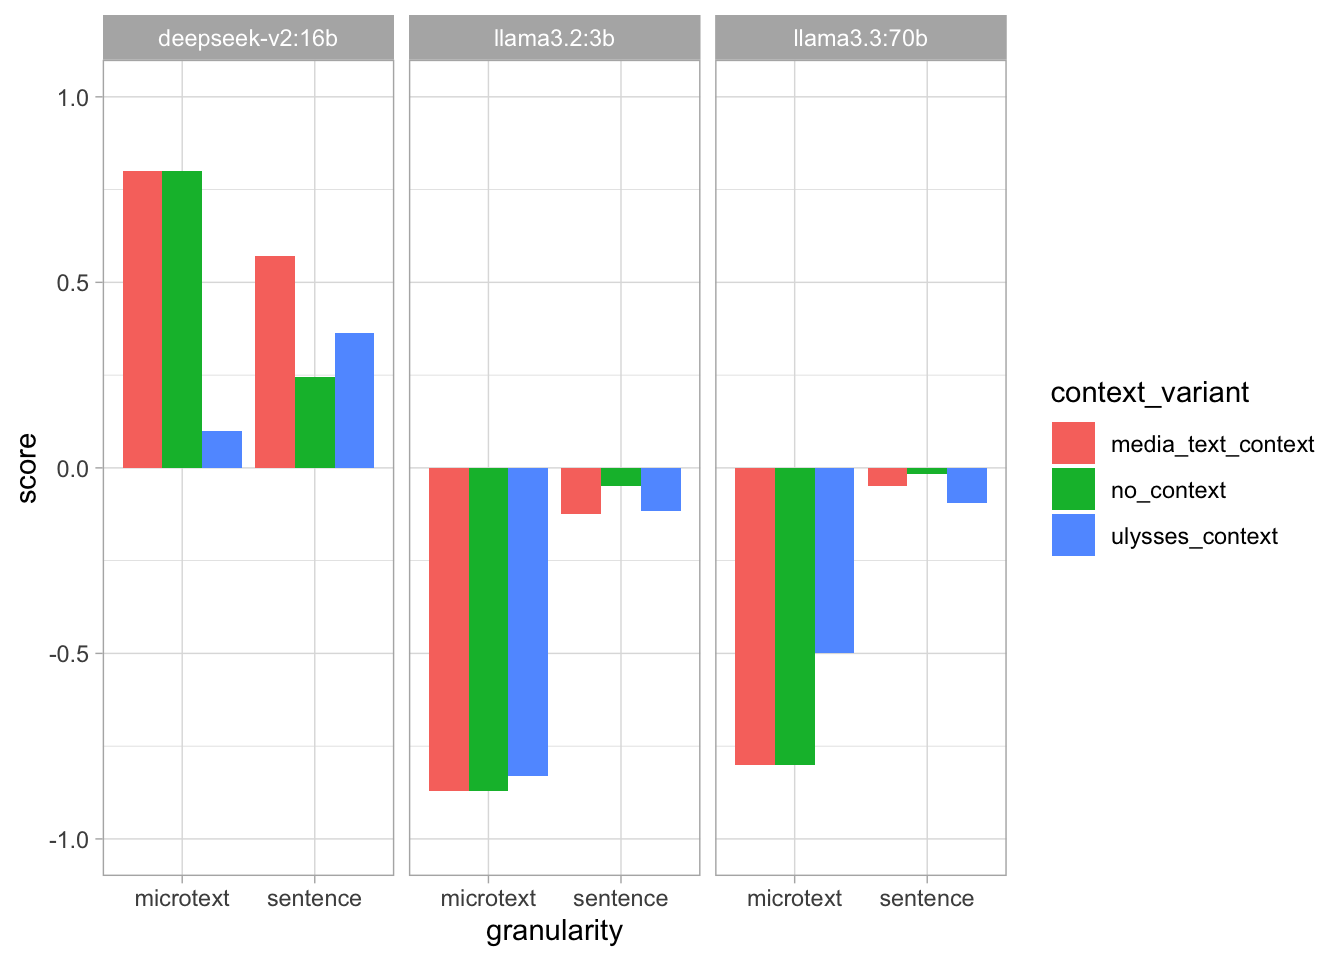
<figcaption>(a) LLM scores</figcaption>
</figure>
</div></td>
<td style="text-align: left;"><div class="cell-output-display" width="50.0%" data-layout-align="left">
<figure id="fig-close-reading-2">
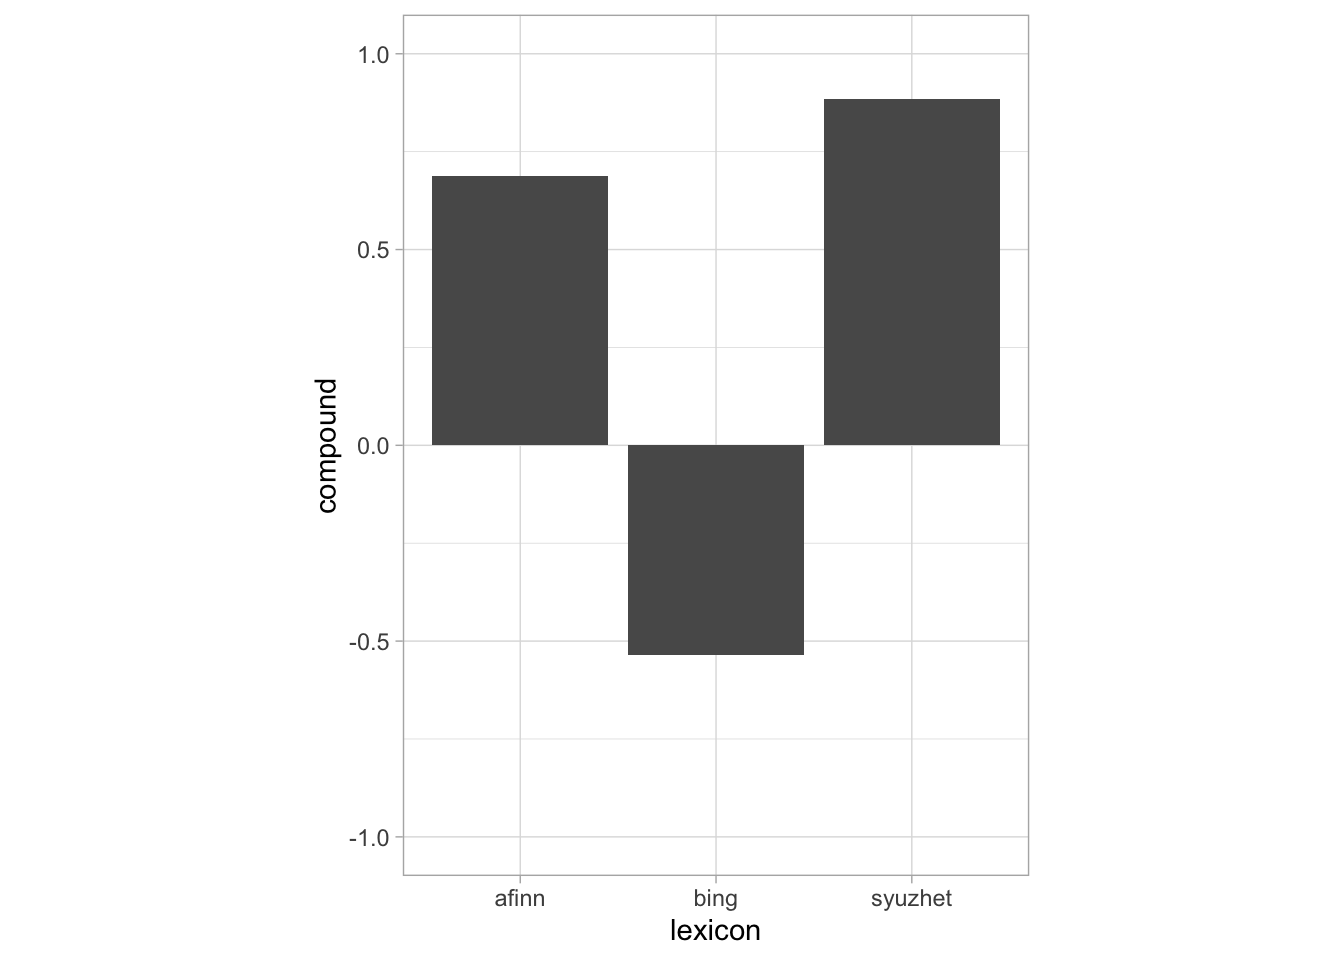
<figcaption>(b) Lexicon scores</figcaption>
</figure>
</div></td>
</tr>
</tbody>
</table>

Figure 4: Sentiment scores for Microtext #45.

In our perspective, Microtext #45 does not have a strong emotional polarity. It certainly contains negative sentiments, but these are refracted through quotation. The microtext has four main components: the headline (“FROM THE FATHERS”); one character’s inner monologue (Stephen’s); another character’s recitation of a nationalist, anti-Semitic speech printed in the newspaper (J. J. O’Molloy reciting John F. Taylor); and the narrator’s bemused comments on the action.

As we will show in the presentation, out initial LLM results give us few clues about how to interpret the texture of this passage. They give the entire microtext a score, without any clues as to what features of the text have influenced the score. By contrast, the lexicon-based approach immediately draws the reader’s attention to sentiment-laden words (<a href="#tbl-45-words" class="quarto-xref">Table 4</a>), which provides a basis for critical discussion. Which words are identified as sentiment-laden? Is this machine judgment reasonable in the context of the microtext? How do these judgements prompt us to re-read the passage?

In [ ]:
classic_sentiment_analysis |> 
  dplyr::filter(microtext == 45) |> 
  dplyr::filter(!is.na(afinn) | !is.na(bing) | !is.na(syuzhet)) |> 
  dplyr::group_by(word) |> 
  dplyr::mutate(n = dplyr::n()) |> 
  dplyr::slice_head(n=1) |> 
  dplyr::select(word, n, afinn, bing, syuzhet) |> 
  knitr::kable()

# 7. Conclusion: Next Steps

This is a work-in-progress presentation, so we conclude with our plans for future work. We have 3 key plans:

1.  Repeat the experiments with larger and more recent LLMs, now that we have access to a more recent version of Ollama. We expect that larger and more capable models will be more reliable, though there are good reasons to doubt this.
2.  Include a “reasoning” field in the research question schemas, so that LLMs are obliged to provide a rationale for their scores. This may increase the interpretability of the results, thus making them more useful for close reading.
3.  Construct a dataset of human scores to for a third point of validation.
4.  Quantify our notions of “calibration,” “discrimination” and “prompt sensitivity” (adapting Rabanser et al. ([2026](#ref-rabanser_towards_2026))) to help develop a shared computational language for evaluating LLM research assistants.

In the long run, LLMs will only be useful for literary criticism if they can be effectively harnessed to enrich our subjective experience of texts. This new technology has not altered the fundamental aim of algorithmic criticism: to “channel the heightened objectivity made possible by the machine into the cultivation of those heightened subjectivities necessary for critical work” ([Ramsay 2011](#ref-ramsay_reading_2011), ix).

# 8. Appendices

## 8.1 Appendix 1: Nationalism and User-Generated Content

In addition to sentiment analysis, we also performed thematic analysis using the LLMs. Initial results are shown here for interest.

The second task we gave the LLMs was: Classify the nationalist orientation of this text. Results were similar to the sentiment analysis questions. All the models showed good calibration (the numerical score corresponded to the label given by the model), but varied in their prompt sensitivity and judgments.

In [ ]:
results |> 
  dplyr::filter(granularity == "microtext", include_headlines == TRUE, research_question == "nationalism") |>
  dplyr::mutate(label = factor(label, levels = c("anti-nationalist", "ambivalent", "nationalist"))) |> 
  llm_facetted_barplot()

In [ ]:
results |> 
  dplyr::filter(granularity == "sentence", include_headlines == TRUE, research_question == "nationalism") |> 
  dplyr::mutate(
    label = dplyr::case_match(
      label,
      "anti-nationalist" ~ -1,
      "ambivalent"  ~ 0,
      "nationalist" ~ 1,
    )
  ) |> 
  dplyr::group_by(model, context_variant, microtext) |> 
  dplyr::summarise(
    label = mean(label),
    label = cut(label, breaks = c(-1, -.3, .3, 1), labels = c("anti-nationalist", "ambivalent", "nationalist"), include.lowest = TRUE),
    score = mean(score)
  ) |> 
  llm_facetted_barplot()

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by model, context_variant, and microtext.
ℹ Output is grouped by model and context_variant.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(model, context_variant, microtext))` for per-operation
  grouping (`?dplyr::dplyr_by`) instead.

The third task we gave the LLMs was: Judge the resemblance of this text to typical user-generated content. Here the two smaller models failed. Their calibration was maximally poor: they labelled every microtext as “ugc” even if awarding a negative score. This poor calibration was repeated when the LLMs analysed the microtexts on the sentence level. The larger model showed good calibration and discrimination: the ‘Aeolus’ episode comments ironically on media discourse; the actual fabric of the episode, with its dialogue and streams of consciousness, rarely resembles media discourse on the surface.

The poor results may have been the fault of our research question schema. Due to an oversight, the LLM was only given two labels to choose from: `"ugc"` and `"other"`. There was no third label for results in the middle of the scale. Since in our setup, the LLM outputs the label before it outputs the numerical score, the numerical score directly depends on the label. It is surprising that the calibration between score and label was so poor on two of the models despite this.

In [ ]:
results |> 
  dplyr::filter(granularity == "microtext", include_headlines == TRUE, research_question == "ugc") |> 
  dplyr::mutate(label = factor(label, levels = c("other", "[uncertain]", "ugc"))) |> 
  llm_facetted_barplot() +
  ggplot2::scale_fill_discrete(drop=FALSE)

In [ ]:
results |> 
  dplyr::filter(granularity == "sentence", include_headlines == TRUE, research_question == "ugc") |>
  dplyr::mutate(
    label = dplyr::case_match(
      label,
      "other" ~ -1,
      "ugc" ~ 1,
    )
  ) |> 
  dplyr::group_by(model, context_variant, microtext) |> 
  dplyr::summarise(
    label = mean(label),
    label = cut(label, breaks = c(-1, -.3, .3, 1), labels = c("other", "[uncertain]", "ugc"), include.lowest = TRUE),
    score = mean(score)
  ) |> 
  llm_facetted_barplot()

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by model, context_variant, and microtext.
ℹ Output is grouped by model and context_variant.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(model, context_variant, microtext))` for per-operation
  grouping (`?dplyr::dplyr_by`) instead.

## 8.2 Appendix 2: Normalising the lexicon-based sentiment scores.

The LLMs were asked to score the microtexts between -1 and 1 on all three tasks. To compare these LLM scores with the lexicon-based scores, we therefore converted the lexicon-based scores to a numerical scale. We adapted the method of Hutto and Gilbert ([2014](#ref-hutto_vader_2014)), shown in <a href="#eq-vader-normalisation" class="quarto-xref">Equation 1</a>.

<span id="eq-vader-normalisation">$$
compound = \frac{sum(pos) + sum(neg)}{\sqrt{(sum(pos) + sum(neg))^2 + \alpha}}
 \qquad(1)$$</span>

Where $pos$ is the sum of positively-scored words in the text, $neg$ is the sum of negatively-scored words, and $\alpha$ is the expected maximum score for a given text. VADER gives a score between -4 and 4 for each word, and is calibrated to short social media texts such as tweets. They empirically determined $\alpha$ to be $15$. Since two of our lexicons, *bing* and *afinn*, simply give a text label to each word (`"positive"` or `"negative"`), we determined $\alpha$ differently. We convert the labels to a $-1$ and $1$, and then inspect the distribution (<a href="#fig-classic-scores-dist" class="quarto-xref">Figure 9</a>). Although *syuzhet* occasionally returns more extreme scores, we determine $10$ as the most appropriate value for $\alpha$ on our scale.

In [ ]:
classic_sentiment_scores |> 
  ggplot2::ggplot(ggplot2::aes(x = total)) + 
  ggplot2::geom_histogram(binwidth = 1) + 
  ggplot2::facet_wrap(ggplot2::vars(lexicon)) +
  ggplot2::labs(
    x = "sum(pos) + sum(neg)",
    y = "Count of Microtexts"
  ) +
  # y-axis should have integer breaks: discrete!
  ggplot2::scale_y_continuous(breaks = scales::breaks_pretty()) +
  ggplot2::theme_light()

# 9. AI Declaration

We used Posit Assistant to assist writing the orchestration code and to document our design decisions for the research compendium. All agent-facing documentation is available in the Github repository for this project in the `docs/` directory or the project root. The code in this abstract was hand-written, with occasional recourse to AI to help identify bugs. All code in the project, whether handwritten or drafted with AI assistance, has been reviewed line-by-line by a human, and we take full responsibility for every line.

All prose in this abstract was human-authored without exception.

# 10. References

Barke, Shraddha, and Adithya Murali. 2026. “Agents as Software: A Programming Languages Agenda for Agent Reliability.” *Proceedings of the 2026 ACM SIGPLAN International Symposium on New Ideas, New Paradigms, and Reflections on Programming and Software* (New York, NY, USA), Onward! ’26, October, 179–90. <https://doi.org/10.1145/3840586.3843744>.

Elkins, Katherine. 2022. *The Shapes of Stories: Sentiment Analysis for Narrative*. Cambridge University Press. <https://doi.org/10.1017/9781009270403>.

Falk, Michael. 2024. *Romanticism and the Contingent Self: The Challenge of Representation*. Palgrave Studies in the Enlightenment, Romanticism and Cultures of Print. Springer International Publishing. <https://doi.org/10.1007/978-3-031-49959-3>.

Franta, Andrew, and Sean Silver. 2024. “Sentiment Analysis and the Sentimental Novel.” *Critical Inquiry* 50 (3): 402–24. <https://doi.org/10.1086/728948>.

Goebel, Randy, Ajay Chander, Katharina Holzinger, et al. 2018. “Explainable AI: The New 42?” In *Machine Learning and Knowledge Extraction*, edited by Andreas Holzinger, Peter Kieseberg, A Min Tjoa, and Edgar Weippl. Lecture Notes in Computer Science. Springer International Publishing. <https://doi.org/10.1007/978-3-319-99740-7_21>.

Hu, Minqing, and Bing Liu. 2004. “Mining and Summarizing Customer Reviews.” *Proceedings of the Tenth ACM SIGKDD International Conference on Knowledge Discovery and Data Mining* (New York, NY, USA), KDD ’04, August, 168–77. <https://doi.org/10.1145/1014052.1014073>.

Hutto, C., and Eric Gilbert. 2014. “VADER: A Parsimonious Rule-Based Model for Sentiment Analysis of Social Media Text.” *Proceedings of the International AAAI Conference on Web and Social Media* 8 (1): 216–25. <https://doi.org/10.1609/icwsm.v8i1.14550>.

Jockers, Matthew. 2015. *Syuzhet: Extract Sentiment and Plot Arcs from Text*. <https://github.com/mjockers/syuzhet>.

Kim, Hoyeol. 2022. “Sentiment Analysis: Limits and Progress of the Syuzhet Package and Its Lexicons.” *Digital Humanities Quarterly* 016 (2).

Lawrence, Karen R. 1980. “"Aeolus": Interruption and Inventory.” *James Joyce Quarterly* 17 (4): 389–405. <https://www.jstor.org/stable/25476319>.

Marwick, Ben, Carl Boettiger, and Lincoln Mullen. 2018. “Packaging Data Analytical Work Reproducibly Using R (and Friends).” *The American Statistician* 72 (1): 80–88. <https://doi.org/10.1080/00031305.2017.1375986>.

McLuhan, Marshall. 1954. “Joyce, Mallarmé, and the Press.” *The Sewanee Review* 62 (1): 38–55. <https://www.jstor.org/stable/27538333>.

Mens, Gaël Le, and Aina Gallego. 2025. “Positioning Political Texts with Large Language Models by Asking and Averaging.” *Political Analysis* 33 (3): 274–82. <https://doi.org/10.1017/pan.2024.29>.

Nielsen, Finn Årup. 2011. “A New ANEW: Evaluation of a Word List for Sentiment Analysis in Microblogs.” *CoRR* abs/1103.2903. <https://doi.org/10.48550/ARXIV.1103.2903>.

Ornstein, Joseph T., Elise N. Blasingame, and Jake S. Truscott. 2025. “How to Train Your Stochastic Parrot: Large Language Models for Political Texts.” *Political Science Research and Methods* 13 (2): 264–81. <https://doi.org/10.1017/psrm.2024.64>.

Rabanser, Stephan, Sayash Kapoor, Peter Kirgis, Kangheng Liu, Saiteja Utpala, and Arvind Narayanan. 2026. *Towards a Science of AI Agent Reliability*. arXiv. <https://doi.org/10.48550/arXiv.2602.16666>.

Radak, Tamara. 2017. “"Aeolus”, Interrupted: Heady Headlines and Joycean Negotiations of Closure.” In *Publishing in Joyce’s *Ulysses**, edited by William Brockman, Tekla Mecsnóber, and Sabrina Alonso. BRILL. <https://doi.org/10.1163/9789004359062_011>.

Ramsay, Stephen. 2011. *Reading Machines: Towards an Algorithmic Criticism*. University of Illinois Press.

Schneider, Ulrich. 1989. “Mediatization in "Aeolus" and "Oxen of the Sun".” *European Joyce Studies* 1: 15–21. <https://www.jstor.org/stable/44871172>.

“Structured Model Outputs OpenAI API.” n.d. In *OpenAI Developers*. Accessed November 11, 2026. <https://developers.openai.com/api/docs/guides/structured-outputs>.